# 19 · Análisis exploratorio: tamaño de los árboles sobre el banco temporal

**Etapa 24 del plan.** Los hiperparámetros salieron del `03`: Optuna por AUC, con la variante `A`, 2 meses de entrenamiento y sin peso en `BAJA+2`. Nunca se revisaron en el banco temporal. En el `18`, cambiar `min_data_in_leaf` movió 7 M por mes, y la cátedra de 2021 elegía de 119 a 989 hojas contra nuestras 50.

**Pregunta:** ¿qué combinación de `num_leaves` y `min_data_in_leaf` gana más dinero con `ACH_4_P3`, y cuánto más que la vigente (50 hojas de al menos 764 filas)?

**Grilla:** `num_leaves` en 25, 50, 100, 200 y 400; `min_data_in_leaf` en 100, 200, 400, 764, 1.500 y 3.000. Son 30 combinaciones, con la vigente adentro. Lo demás queda fijo: columnas de `ACH_4`, peso 3 en `BAJA+2`, `learning_rate`, `feature_fraction`, `bagging_fraction` y 296 árboles.

| Fase | Meses | Semillas | Para qué |
|---|---|---:|---|
| **Búsqueda** | 201906, 201907, 201908 | 1 | Elegir la combinación con más ganancia en la banda |
| **Confirmación** | 201909, 201910 | 5 | Medir la elegida contra `ACH_4_P3`, en meses que no se usaron para elegir |

Mismo banco temporal del `15`: para evaluar un mes, el modelo entrena con todos los meses desde 201903 hasta dos meses antes.

**Todo lo de este notebook es exploratorio.** No cambia el resultado de la regla pre-registrada. No carga 201911 ni 201912. **No escribe en `exp/03/` a `exp/18/` ni en los `resultados/03_*` a `18_*`:** solo los lee.

Ficha: `fichas/etapa_24_hojas.md` (en el laboratorio).

## 1. Parámetros

**Retomar:** si la corrida se corta, se vuelve a correr entera. Los modelos ya hechos no se repiten, y la elección guardada se comprueba.

In [1]:
from pathlib import Path
import gc
import hashlib
import json
import resource
import sys
import time
import warnings

import duckdb
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter
from scipy import stats
from sklearn.metrics import roc_auc_score

# --- Parámetros -------------------------------------------------------------
BASE_PARQUET = Path('../data/base_2019.parquet')
RESULTADOS = Path('../resultados')
EXP_15 = Path('../exp/15')                          # solo se lee
EXP = Path('../exp/19')
FIGURAS = RESULTADOS / 'figuras'

MES_TOPE = 201910                                   # nada posterior entra a este notebook
MESES_TABLA = [201903, 201904, 201905, 201906, 201907, 201908, 201909, 201910]
MESES_EVALUADOS = [201906, 201907, 201908, 201909, 201910]
MESES_FINALES = [201909, 201910]
MESES_CONSIGNA = [201903, 201904, 201905, 201906]
ULTIMOS = 4
DISTANCIA = 2                                       # la clase de un mes se conoce dos meses después
MESES_TRAIN = MESES_CONSIGNA                        # los pide `construir`; acá cada modelo elige su ventana
MESES_EVAL = MESES_FINALES
ROTOS_EXTRA = [('ctarjeta_master_descuentos', 201910), ('mtarjeta_master_descuentos', 201910)]   # como en el 06 y el 12

CONTROL = 'AC'
BASE_CURADA = 'ACH'
JUNTAS = 'ACH_4'
NUEVAS = {'ACH': {'lags': [], 'tendencia': None, 'curada': True}}
CANDIDATAS = ['ACH_V', 'ACH_Q', 'ACH_T', 'ACH_Z']
REFERENCIA = 'ACH_4_P3'                             # la vigente del 15: sus predicciones se leen de exp/15
PESO_B2 = 3
GRILLA_HOJAS = [25, 50, 100, 200, 400]              # num_leaves
GRILLA_TAMANO = [100, 200, 400, 764, 1_500, 3_000]  # min_data_in_leaf
VIGENTE = (50, 764)
MESES_BUSQUEDA = [201906, 201907, 201908]           # eligen, con una semilla
MESES_CONFIRMA = [201909, 201910]                   # confirman, con 5 semillas
HIPOTESIS = 'Con otro num_leaves y otro min_data_in_leaf, ACH_4_P3 gana más dinero'
UMBRAL = 1.0                                        # M por mes, fijado en la ficha
FOTOS = 9                                           # 201910 llega hasta 201901

N_CURADAS = 30
MINIMO_PREVIOS = 2
BLOQUE = 20_000                                     # filas por bloque al armar las tablas

SEMILLA_PRIMIGENIA = 979201
N_SEMILLAS = 5
N_BOOTSTRAP = 2_000
BANDA = (3_000, 6_000)                              # ambos incluidos
EPSILON = 1e-12
POSITIVOS = ['BAJA+1', 'BAJA+2']
N_HILOS = 8

GANANCIA_ACIERTO = 1_072_500
COSTO_ESTIMULO = 27_500
LARGO_CURVA = 25_000
# -----------------------------------------------------------------------------

PRED = EXP / 'pred'
VARIABLES_CSV = RESULTADOS / '08_variables.csv'     # solo se lee
for d in (PRED, FIGURAS):
    d.mkdir(parents=True, exist_ok=True)
warnings.filterwarnings('ignore', message='.*ChainedAssignmentError.*')  # falso positivo pandas 2.2 + Py 3.14

ESPERADO_FILAS_POR_MES = {
    201901: 123_916, 201902: 125_020, 201903: 125_622, 201904: 126_116, 201905: 126_763,
    201906: 128_370, 201907: 129_853, 201908: 131_775, 201909: 133_419, 201910: 135_633,
}
ESPERADO_TABLA = (1_037_551, 5_042)                 # filas, BAJA+2
ESPERADO_N_VARIABLES = {'AC': 760, 'ACH': 880, 'ACH_4': 1_180}
N_MES = 152
ESPERADO_ROTOS = 23


def primos_6_digitos():
    criba = np.ones(1_000_000, dtype=bool)
    criba[:2] = False
    for i in range(2, 1_001):
        if criba[i]:
            criba[i * i::i] = False
    return np.flatnonzero(criba[100_000:]) + 100_000


TODAS = np.random.default_rng(SEMILLA_PRIMIGENIA).choice(primos_6_digitos(), size=20, replace=False).tolist()[:10]
assert TODAS == [294103, 342929, 161093, 677561, 431077, 330679, 511579, 312773, 118147, 567529]
SEMILLAS = TODAS[:N_SEMILLAS]


def huella_archivos():
    """Control 8: huella de las salidas anteriores, para comprobar que no cambian."""
    archivos = [*RESULTADOS.glob('0[3456789]_*'), *RESULTADOS.glob('1[012345678]_*')]
    return {p.name: hashlib.blake2b(p.read_bytes(), digest_size=16).hexdigest() for p in sorted(archivos)}


def memoria_gb():
    r = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss
    return round(r / (1e9 if sys.platform == 'darwin' else 1e6), 1)


HUELLA_INICIAL = huella_archivos()
T_INICIO = time.time()
print('Salidas anteriores registradas:', len(HUELLA_INICIAL))

Salidas anteriores registradas: 52


## 2. Dataset y funciones de evaluación

**Control 1:** filas y `BAJA+2` de 201903 a 201910. **Control 2:** nada posterior a 201910 entra al notebook. La clase de 201911 y 201912 nunca se carga.

In [2]:
def curva(prob, es_b2):
    orden = np.argsort(-prob, kind='stable')
    return np.cumsum(np.where(es_b2[orden], GANANCIA_ACIERTO, -COSTO_ESTIMULO))[:LARGO_CURVA].astype(np.float64)


def banda(cv):
    return cv[..., BANDA[0] - 1:BANDA[1]].mean(axis=-1)


HIPER = json.loads((RESULTADOS / '03_hiperparametros.json').read_text())

t0 = time.time()
con = duckdb.connect()
base = con.execute(f"""
    select * from read_parquet('{BASE_PARQUET.as_posix()}')
    where foto_mes <= {MES_TOPE}
    order by foto_mes, numero_de_cliente
""").df()
con.close()
assert base['foto_mes'].max() == MES_TOPE                                 # control 2
assert base['foto_mes'].value_counts().sort_index().to_dict() == ESPERADO_FILAS_POR_MES

CLAVES = ['numero_de_cliente', 'foto_mes', 'clase_ternaria']
VARIABLES = [c for c in base.columns if c not in CLAVES]
BANDERAS = ['active_quarter', 'cliente_vip', 'internet', 'cdescubierto_preacordado',
            'tcallcenter', 'thomebanking', 'tmobile_app', 'ccajas_transacciones']
ESTADOS = ['tcuentas', 'Visa_status', 'Master_status', 'Visa_delinquency', 'Master_delinquency']
FECHAS = [f'{t}_{c}' for t in ('Visa', 'Master') for c in ('Fvencimiento', 'Finiciomora', 'fultimo_cierre', 'fechaalta')]
EDADES = ['cliente_edad', 'cliente_antiguedad']
MONTOS = [v for v in VARIABLES if v not in BANDERAS + ESTADOS + FECHAS + EDADES]
assert len(VARIABLES) == 152 and len(MONTOS) == 129

rotos = pd.read_csv(RESULTADOS / '01_meses_rotos.csv')[['variable', 'foto_mes']]
assert len(rotos) == ESPERADO_ROTOS
rotos = pd.concat([rotos, pd.DataFrame(ROTOS_EXTRA, columns=['variable', 'foto_mes'])], ignore_index=True)
for v, mes in rotos.itertuples(index=False):
    base.loc[base['foto_mes'] == mes, v] = np.nan

FOTO_MES = base['foto_mes'].to_numpy()
PERIODO = (FOTO_MES // 100 * 12 + FOTO_MES % 100).astype(np.int64)
CLAVE = base['numero_de_cliente'].to_numpy(np.int64) * 100_000 + PERIODO
INDICE = pd.Index(CLAVE)
assert INDICE.is_unique
X_MES = np.asfortranarray(base[VARIABLES].to_numpy(np.float32))
CLASE = base['clase_ternaria'].to_numpy()
del base
gc.collect()
print(f'Dataset cargado en {time.time() - t0:.0f} s')

Dataset cargado en 1 s


## 3. Tablas de `ACH_4`

Las mismas columnas de `ACH_4` del `15`: 1.180, el baseline más la historia curada y los cuatro bloques del `14`.

**Control 4:** una columna da lo mismo calculada solo con datos hasta su mes. **Control 6:** fórmulas a mano en 300 clientes.

In [3]:
SIN_HISTORIA = {'lags': [], 'tendencia': None, 'curada': False}


def receta(config):
    return SIN_HISTORIA if config == CONTROL else NUEVAS[config]


def especificacion(config):
    ex = receta(config)
    e = [('original', v, 0) for v in VARIABLES]
    e += [(op, v, k) for k in (1, 2) for op in ('lag', 'delta') for v in VARIABLES]
    for k in ex['lags']:
        e += [(op, v, k) for op in ('lag', 'delta') for v in MONTOS + BANDERAS]
        e += [(op, v, k) for op in ('lag', 'cambio') for v in ESTADOS]
    if ex['tendencia']:
        h = ex['tendencia']
        e += [(op, v, h) for op in ('pend', 'prom', 'min', 'max') for v in MONTOS]
        e += [('perm', v, h) for v in BANDERAS]
    if ex['curada']:
        assert len(CURADAS) == N_CURADAS
        e += [(op, v, k) for op, k in (('ratio', 3), ('z', 4), ('relmax', 4), ('mes_ratio', 3)) for v in CURADAS]
    return e


def nombre(op, v, k):
    return v if op == 'original' else f'{v}_{op}{k}'


def construir(config, meses=None):
    ex = receta(config)
    h = ex['tendencia']
    h_max = max([2] + ex['lags'] + [h or 0] + ([4] if ex['curada'] else []))
    filas = np.flatnonzero(np.isin(FOTO_MES, meses or MESES_TRAIN + MESES_EVAL))
    mes_fila = FOTO_MES[filas]
    n_train = int(np.isin(mes_fila, MESES_TRAIN).sum())
    assert meses or (np.isin(mes_fila[:n_train], MESES_TRAIN).all() and np.isin(mes_fila[n_train:], MESES_EVAL).all())
    pos = {k: INDICE.get_indexer(CLAVE[filas] - k) for k in range(h_max + 1)}

    espec = especificacion(config)
    ubic = {e: i for i, e in enumerate(espec)}
    F = np.empty((len(filas), len(espec)), dtype=np.float32)
    t = -np.arange((h or 0) + 1, dtype=np.float64)[:, None]
    # Por bloques de filas: escribir columna por columna recorre toda la tabla en cada pasada,
    # y con una tabla de más de ~4,5 GB eso tardó decenas de minutos.
    with np.errstate(invalid='ignore', divide='ignore'):
        for inicio in range(0, len(filas), BLOQUE):
            fb = slice(inicio, inicio + BLOQUE)
            for j, v in enumerate(VARIABLES):
                F[fb, ubic[('original', v, 0)]] = X_MES[filas[fb], j]
                hk = {}
                for k in range(h_max + 1):
                    col = X_MES[pos[k][fb], j]
                    col[pos[k][fb] < 0] = np.nan
                    hk[k] = col
                for k in range(1, h_max + 1):
                    if ('lag', v, k) in ubic:
                        F[fb, ubic[('lag', v, k)]] = hk[k]
                    if ('delta', v, k) in ubic:
                        F[fb, ubic[('delta', v, k)]] = hk[0] - hk[k]
                    if ('cambio', v, k) in ubic:
                        a, b = hk[0], hk[k]
                        F[fb, ubic[('cambio', v, k)]] = np.where(np.isnan(a) | np.isnan(b), np.nan, (a != b).astype(np.float32))
                if h and (('prom', v, h) in ubic or ('perm', v, h) in ubic):
                    S = np.stack([hk[k] for k in range(h + 1)]).astype(np.float64)
                    valido = ~np.isnan(S)
                    cuantos = valido.sum(axis=0)
                    S0 = np.where(valido, S, 0.0)
                    if ('perm', v, h) in ubic:
                        F[fb, ubic[('perm', v, h)]] = np.where(cuantos > 0, S0.sum(axis=0), np.nan)
                    else:
                        prom = S0.sum(axis=0) / cuantos
                        dt = np.where(valido, t - (valido * t).sum(axis=0) / cuantos, 0.0)
                        pend = (dt * (S0 - prom)).sum(axis=0) / (dt ** 2).sum(axis=0)
                        pend[cuantos < 2] = np.nan
                        F[fb, ubic[('pend', v, h)]] = pend
                        F[fb, ubic[('prom', v, h)]] = prom
                        F[fb, ubic[('min', v, h)]] = np.where(cuantos > 0, np.where(valido, S, np.inf).min(axis=0), np.nan)
                        F[fb, ubic[('max', v, h)]] = np.where(cuantos > 0, np.where(valido, S, -np.inf).max(axis=0), np.nan)
                if ('ratio', v, 3) in ubic:
                    a, b, c = (hk[k].astype(np.float64) for k in range(3))
                    media3 = (a + b + c) / 3                  # NA si falta alguna foto
                    ratio = np.where(np.abs(media3) > EPSILON, a / media3, np.nan)
                    F[fb, ubic[('ratio', v, 3)]] = ratio
                    x = a
                    P = np.stack([hk[k] for k in range(1, 5)]).astype(np.float64)
                    valido = ~np.isnan(P)
                    cuantos = valido.sum(axis=0)
                    alcanza = (cuantos >= MINIMO_PREVIOS) & ~np.isnan(x)
                    media = np.where(valido, P, 0.0).sum(axis=0) / cuantos
                    desvio = np.sqrt(np.where(valido, (P - media) ** 2, 0.0).sum(axis=0) / cuantos)
                    maximo = np.where(valido, P, -np.inf).max(axis=0)
                    F[fb, ubic[('z', v, 4)]] = np.where(alcanza & (desvio > EPSILON), (x - media) / desvio, np.nan)
                    F[fb, ubic[('relmax', v, 4)]] = np.where(alcanza & (maximo > EPSILON), x / maximo, np.nan)
    for v in (CURADAS if ex['curada'] else []):           # el percentil necesita el mes entero
        F[:, ubic[('mes_ratio', v, 3)]] = pd.Series(F[:, ubic[('ratio', v, 3)]]).groupby(mes_fila).rank(pct=True).to_numpy(np.float32)
    return {'F': F, 'columnas': [nombre(*e) for e in espec], 'espec': espec, 'filas': filas, 'mes_fila': mes_fila,
            'n_train': n_train, 'lags': sorted({k for op, _, k in espec if op == 'lag'}), 'h': h}


CURADAS = pd.read_csv(VARIABLES_CSV)['variable'].tolist()
assert len(CURADAS) == N_CURADAS and set(CURADAS) <= set(MONTOS)


def cero_fijo(x, mes):
    """Percentil dentro del mes: positivos de 0 a 1, negativos de 0 a -1, y el cero en 0."""
    s = pd.Series(x)
    arriba = s.where(s > 0).groupby(mes).rank(pct=True).fillna(0)
    abajo = (-s).where(s < 0).groupby(mes).rank(pct=True).fillna(0)
    return (arriba - abajo).where(s.notna()).to_numpy()


def bloques_nuevos(filas, X, indice, clave, foto_mes):
    """Cada fila usa solo fotos de su mes o anteriores. El percentil usa solo su mes."""
    pos = [indice.get_indexer(clave[filas] - k) for k in range(FOTOS + 1)]
    mes = foto_mes[filas]
    salida = {b: {} for b in CANDIDATAS}
    with np.errstate(invalid='ignore', divide='ignore'):
        for v in CURADAS:
            j = VARIABLES.index(v)
            H = np.stack([np.where(p >= 0, X[p, j], np.nan) for p in pos]).astype(np.float64)
            a, b, c, d = H[:4]
            dif = np.stack([a - b, b - c, c - d])
            valido = ~np.isnan(dif)
            cuantos = valido.sum(axis=0)
            alcanza = cuantos >= MINIMO_PREVIOS
            media = np.where(valido, dif, 0.0).sum(axis=0) / cuantos
            desvio = np.sqrt(np.where(valido, (dif - media) ** 2, 0.0).sum(axis=0) / cuantos)
            salida['ACH_V'][f'{v}_std3'] = np.stack([a, b, c]).std(axis=0)
            salida['ACH_V'][f'{v}_dstd3'] = np.where(alcanza, desvio, np.nan)
            salida['ACH_Q'][f'{v}_q4'] = (a + b) / 2 - (c + d) / 2
            salida['ACH_Q'][f'{v}_peor3'] = np.where(alcanza, np.where(valido, dif, np.inf).min(axis=0), np.nan)
            salida['ACH_Q'][f'{v}_caidas3'] = np.where(alcanza, (dif < 0).sum(axis=0), np.nan)
            P = H[1:]
            valido = ~np.isnan(P)
            cuantos = valido.sum(axis=0)
            alcanza = (cuantos >= MINIMO_PREVIOS) & ~np.isnan(a)
            maximo = np.where(valido, P, -np.inf).max(axis=0)
            media = np.where(valido, P, 0.0).sum(axis=0) / cuantos
            salida['ACH_T'][f'{v}_relmaxT'] = np.where(alcanza & (maximo > EPSILON), a / maximo, np.nan)
            salida['ACH_T'][f'{v}_relmediaT'] = np.where(alcanza & (np.abs(media) > EPSILON), a / media, np.nan)
            salida['ACH_T'][f'{v}_desdemaxT'] = np.where(alcanza, np.where(np.isnan(H), -np.inf, H).argmax(axis=0), np.nan)
            salida['ACH_Z'][f'{v}_zc1'] = cero_fijo(a - b, mes)
            salida['ACH_Z'][f'{v}_zc2'] = cero_fijo(a - c, mes)
    return {b: (np.column_stack(list(c.values())).astype(np.float32), list(c)) for b, c in salida.items()}


t0 = time.time()
T = construir(BASE_CURADA, meses=MESES_TABLA)
assert T['F'].shape == (ESPERADO_TABLA[0], ESPERADO_N_VARIABLES[BASE_CURADA]), T['F'].shape
assert T['columnas'][:N_MES] == VARIABLES and T['columnas'][ESPERADO_N_VARIABLES[CONTROL]].endswith('_ratio3')
assert (CLASE[T['filas']] == 'BAJA+2').sum() == ESPERADO_TABLA[1]         # control 1
B = bloques_nuevos(T['filas'], X_MES, INDICE, CLAVE, FOTO_MES)
assert {b: v[0].shape[1] for b, v in B.items()} == {'ACH_V': 60, 'ACH_Q': 90, 'ACH_T': 90, 'ACH_Z': 60}

CLIENTE_FILA = CLAVE[T['filas']] // 100_000
CLIENTES, POS_CLIENTE = np.unique(CLIENTE_FILA, return_inverse=True)

# Control 4: sin fuga. Con los datos cortados en el mes, cada columna tiene que dar lo mismo.
for corte in (201905, 201906, 201909):
    hasta = FOTO_MES <= corte
    filas_c = np.flatnonzero(FOTO_MES[hasta] == corte)
    C = bloques_nuevos(filas_c, X_MES[hasta], pd.Index(CLAVE[hasta]), CLAVE[hasta], FOTO_MES[hasta])
    en_mes = T['mes_fila'] == corte
    for b in CANDIDATAS:
        assert np.array_equal(C[b][0], B[b][0][en_mes], equal_nan=True), (b, corte)
    del C

# Control 6: fórmulas a mano
rng = np.random.default_rng(SEMILLA_PRIMIGENIA)
muestra = rng.choice(len(T['filas']), size=300, replace=False)
col = {b: {c: i for i, c in enumerate(B[b][1])} for b in CANDIDATAS}


def igual(bloque, nombre_columna, fila, esperado):
    valor = B[bloque][0][fila, col[bloque][nombre_columna]]
    if esperado is None:
        assert np.isnan(valor), (nombre_columna, fila, valor)
    else:
        np.testing.assert_allclose(valor, esperado, rtol=1e-3, atol=1e-3, err_msg=nombre_columna)


for v in CURADAS[:3]:
    serie = pd.Series(X_MES[:, VARIABLES.index(v)].astype(np.float64), index=INDICE)
    for i in muestra:
        clave = CLAVE[T['filas'][i]]
        y = [serie.get(clave - k, np.nan) for k in range(FOTOS + 1)]
        igual('ACH_V', f'{v}_std3', i, None if np.isnan(y[:3]).any() else float(np.std(y[:3])))
        igual('ACH_Q', f'{v}_q4', i, None if np.isnan(y[:4]).any() else (y[0] + y[1]) / 2 - (y[2] + y[3]) / 2)
        dif = [y[k] - y[k + 1] for k in range(3)]
        hay = [x for x in dif if not np.isnan(x)]
        igual('ACH_V', f'{v}_dstd3', i, float(np.std(hay)) if len(hay) >= 2 else None)
        igual('ACH_Q', f'{v}_peor3', i, min(hay) if len(hay) >= 2 else None)
        igual('ACH_Q', f'{v}_caidas3', i, sum(x < 0 for x in hay) if len(hay) >= 2 else None)
        previos = [x for x in y[1:] if not np.isnan(x)]
        alcanza = len(previos) >= 2 and not np.isnan(y[0])
        igual('ACH_T', f'{v}_relmaxT', i, y[0] / max(previos) if alcanza and max(previos) > EPSILON else None)
        igual('ACH_T', f'{v}_relmediaT', i, y[0] / np.mean(previos) if alcanza and abs(np.mean(previos)) > EPSILON else None)
        igual('ACH_T', f'{v}_desdemaxT', i, int(np.nanargmax(y)) if alcanza else None)
v = CURADAS[0]
en_mes = T['mes_fila'] == 201906
d = T['F'][en_mes, T['columnas'].index(f'{v}_delta1')].astype(np.float64)
z = B['ACH_Z'][0][en_mes, col['ACH_Z'][f'{v}_zc1']]
assert (np.isnan(d) == np.isnan(z)).all() and (np.sign(d[~np.isnan(d)]) == np.sign(z[~np.isnan(z)])).all()
hay = d > 0
np.testing.assert_allclose(z[hay], stats.rankdata(d[hay]) / hay.sum(), rtol=1e-5)
print(f'Tablas y controles 4 y 6 OK en {time.time() - t0:.0f} s · memoria máxima {memoria_gb()} GB')

Tablas y controles 4 y 6 OK en 23 s · memoria máxima 5.5 GB


## 4. Ventanas y controles

**Control 3:** ningún modelo entrena con un mes posterior a dos meses antes del evaluado.

**Control 5:** la combinación vigente (50, 764) de 201906, con la primera semilla, da la predicción del `15`. Comprueba que este notebook entrena igual que el `15`: lo único que cambia en la grilla son las hojas y su tamaño.

**Control 11:** las columnas son las 1.180 de `ACH_4`, sin nombres repetidos.

In [4]:
FIJOS = {'objective': 'binary', 'metric': 'auc', 'boosting': 'gbdt', 'max_bin': 31, 'bagging_freq': 1,
         'lambda_l1': 0.0, 'lambda_l2': 0.0, 'min_gain_to_split': 0.0, 'feature_pre_filter': False,
         'num_threads': N_HILOS, 'deterministic': True, 'force_col_wise': True, 'verbose': -1}
HIPER = json.loads((RESULTADOS / '03_hiperparametros.json').read_text())
MEJORES = {**FIJOS, **HIPER['params']}
ARBOLES = HIPER['arboles']
assert ARBOLES == 296 and (MEJORES['num_leaves'], MEJORES['min_data_in_leaf']) == VIGENTE
BINS = {'max_bin': 31, 'feature_pre_filter': False, 'data_random_seed': SEMILLA_PRIMIGENIA}

GRILLA = [(h, t) for h in GRILLA_HOJAS for t in GRILLA_TAMANO]
assert VIGENTE in GRILLA and len(GRILLA) == 30
nombre = lambda h, t: f'H{h}_M{t}'
SEMILLA_BUSQUEDA = SEMILLAS[0]

CLASE_T = CLASE[T['filas']]
ES_B2 = CLASE_T == 'BAJA+2'
es_mes = {m: T['mes_fila'] == m for m in MESES_TABLA}
ENTRENA = {m: [x for x in MESES_TABLA if x <= m - DISTANCIA] for m in MESES_EVALUADOS}
assert all(ENTRENA[m] and max(ENTRENA[m]) <= m - DISTANCIA for m in MESES_EVALUADOS)        # control 3
assert sorted(MESES_BUSQUEDA + MESES_CONFIRMA) == MESES_EVALUADOS


def ruta(config, mes, semilla, que='pred'):
    return EXP / que / config / str(mes) / f'{semilla}.npy'


def tabla_de(filas):
    k = ESPERADO_N_VARIABLES[BASE_CURADA]
    X = np.hstack([T['F'][filas, :k]] + [B[b][0][filas] for b in CANDIDATAS])
    return X, T['columnas'][:k] + [c for b in CANDIDATAS for c in B[b][1]]


def dataset(mes):
    entrena = np.isin(T['mes_fila'], ENTRENA[mes])
    X, columnas = tabla_de(entrena)
    clase = CLASE_T[entrena]
    d = lgb.Dataset(X, label=np.isin(clase, POSITIVOS).astype(np.int8), feature_name=columnas, params=BINS, free_raw_data=True).construct()
    d.set_weight(np.where(clase == 'BAJA+2', PESO_B2, 1).astype(np.float32))
    del X
    return d


def entrenar(dtrain, semilla, hojas, tamano):
    return lgb.train({**MEJORES, 'num_leaves': hojas, 'min_data_in_leaf': tamano, 'seed': semilla,
                      'data_random_seed': SEMILLA_PRIMIGENIA}, dtrain, num_boost_round=ARBOLES)


def correr(hojas, tamano, mes, semilla, dtrain, X_mes):
    t0 = time.time()
    modelo = entrenar(dtrain, semilla, hojas, tamano)
    prob = modelo.predict(X_mes, num_threads=N_HILOS).astype(np.float32)
    for que, valor in (('pred', prob), ('seg', np.array([time.time() - t0, modelo.num_trees()], dtype=np.float64))):
        destino = ruta(nombre(hojas, tamano), mes, semilla, que)
        assert destino.is_relative_to(EXP), destino
        destino.parent.mkdir(parents=True, exist_ok=True)
        np.save(destino, valor)
    return time.time() - t0


print(pd.DataFrame({'meses de entrenamiento': {m: f'{ENTRENA[m][0]}-{ENTRENA[m][-1] % 100:02d}' for m in MESES_EVALUADOS},
                    'filas': {m: int(np.isin(T['mes_fila'], ENTRENA[m]).sum()) for m in MESES_EVALUADOS},
                    'fase': {m: 'búsqueda' if m in MESES_BUSQUEDA else 'confirmación' for m in MESES_EVALUADOS}}).to_string())

# Control 11
COLUMNAS = tabla_de(np.arange(2))[1]
assert len(COLUMNAS) == len(set(COLUMNAS)) == ESPERADO_N_VARIABLES[JUNTAS]

# Control 5
ruta_control = EXP / 'control_5.txt'
if not ruta_control.exists():
    t0 = time.time()
    dtrain = dataset(201906)
    modelo = entrenar(dtrain, SEMILLAS[0], *VIGENTE)
    prob = modelo.predict(tabla_de(es_mes[201906])[0], num_threads=N_HILOS).astype(np.float32)
    assert np.array_equal(prob, np.load(EXP_15 / 'pred' / REFERENCIA / '201906' / f'{SEMILLAS[0]}.npy')), 'ACH_4_P3 no reproduce el 15'
    ruta_control.parent.mkdir(parents=True, exist_ok=True)
    ruta_control.write_text('ok\n')
    del dtrain, modelo, prob
    gc.collect()
    print(f'Control 5 OK en {time.time() - t0:.0f} s')
else:
    print('Control 5 ya hecho')
print('Controles 3 y 11 OK')

       meses de entrenamiento   filas          fase
201906              201903-04  251738      búsqueda
201907              201903-05  378501      búsqueda
201908              201903-06  506871      búsqueda
201909              201903-07  636724  confirmación
201910              201903-08  768499  confirmación
Control 5 OK en 26 s
Controles 3 y 11 OK


## 5. Búsqueda

Las 30 combinaciones en 201906, 201907 y 201908, con la primera semilla. El dataset de cada mes se arma una sola vez y lo usan todas las combinaciones. Algunas combinaciones no se pueden llenar (muchas hojas grandes en pocas filas): LightGBM corta las hojas antes, y se informan como salen.

**Retomar:** cada predicción se guarda al terminar el modelo, con sus segundos.

In [5]:
falta = lambda c, m, s: not ruta(c, m, s).exists()
print('Modelos pendientes en la búsqueda:', sum(falta(nombre(h, t), m, SEMILLA_BUSQUEDA) for h, t in GRILLA for m in MESES_BUSQUEDA))
for m in MESES_BUSQUEDA:
    pendientes = [(h, t) for h, t in GRILLA if falta(nombre(h, t), m, SEMILLA_BUSQUEDA)]
    if not pendientes:
        continue
    t_mes = time.time()
    dtrain = dataset(m)
    X_mes = tabla_de(es_mes[m])[0]
    for h, t in pendientes:
        correr(h, t, m, SEMILLA_BUSQUEDA, dtrain, X_mes)
    print(f'{m}: {len(pendientes)} modelos en {(time.time() - t_mes) / 60:.1f} min · memoria máxima {memoria_gb()} GB', flush=True)
    del dtrain, X_mes
    gc.collect()

assert not any(falta(nombre(h, t), m, SEMILLA_BUSQUEDA) for h, t in GRILLA for m in MESES_BUSQUEDA)   # control 7

Modelos pendientes en la búsqueda: 90
201906: 30 modelos en 16.5 min · memoria máxima 5.5 GB
201907: 30 modelos en 26.4 min · memoria máxima 5.5 GB
201908: 30 modelos en 36.4 min · memoria máxima 5.5 GB


## 6. Elección

**Regla fijada antes de correr:** la combinación con la mayor ganancia en la banda, promediando los 3 meses de búsqueda. Si es la vigente, no hay confirmación y queda `ACH_4_P3`.

**Control 13:** la elección solo lee la clase de 201906, 201907 y 201908. Se guarda antes de la confirmación; al retomar, se comprueba que sale la misma.

In [6]:
def ganancia_busqueda(config, mes):
    assert mes in MESES_BUSQUEDA                                                   # control 13
    p = np.load(ruta(config, mes, SEMILLA_BUSQUEDA))
    y = ES_B2[es_mes[mes]]
    return banda(curva(p, y)) / 1e6, roc_auc_score(y, p)


filas = []
for h, t in GRILLA:
    for m in MESES_BUSQUEDA:
        g, a = ganancia_busqueda(nombre(h, t), m)
        s, n = np.load(ruta(nombre(h, t), m, SEMILLA_BUSQUEDA, 'seg'))
        filas.append({'num_leaves': h, 'min_data_in_leaf': t, 'foto_mes': m, 'ganancia_banda_M': round(g, 4),
                      'auc': round(a, 6), 'segundos': round(s, 1), 'arboles': int(n)})
busqueda = pd.DataFrame(filas)
busqueda.to_csv(RESULTADOS / '19_busqueda.csv', index=False)

MAPA = busqueda.groupby(['num_leaves', 'min_data_in_leaf'])['ganancia_banda_M'].mean().unstack()
ELEGIDA = tuple(int(x) for x in MAPA.stack().idxmax())
ruta_eleccion = EXP / 'eleccion.json'
if ruta_eleccion.exists():
    assert tuple(json.loads(ruta_eleccion.read_text())['elegida']) == ELEGIDA, 'La elección cambió al retomar'
else:
    ruta_eleccion.write_text(json.dumps({'elegida': ELEGIDA, 'ganancia_busqueda_M': float(MAPA.loc[ELEGIDA])}))
CONFIRMA = ELEGIDA != VIGENTE
BORDE = ELEGIDA[0] in (GRILLA_HOJAS[0], GRILLA_HOJAS[-1]) or ELEGIDA[1] in (GRILLA_TAMANO[0], GRILLA_TAMANO[-1])

print('Ganancia media en la banda, 201906-08, una semilla (M por mes). Filas: num_leaves; columnas: min_data_in_leaf')
print(MAPA.round(2).to_string())
print()
print('Diferencia contra la vigente (50, 764):')
print((MAPA - MAPA.loc[VIGENTE]).round(2).to_string())
print()
print('AUC media:')
print(busqueda.groupby(['num_leaves', 'min_data_in_leaf'])['auc'].mean().unstack().round(4).to_string())
print()
print('Segundos por modelo (media de los 3 meses):')
print(busqueda.groupby(['num_leaves', 'min_data_in_leaf'])['segundos'].mean().unstack().round(0).to_string())
print()
print(f'Elegida: num_leaves {ELEGIDA[0]}, min_data_in_leaf {ELEGIDA[1]} · {MAPA.loc[ELEGIDA]:.2f} M · '
      f'{MAPA.loc[ELEGIDA] - MAPA.loc[VIGENTE]:+.2f} M contra la vigente en la búsqueda (inflado: se eligió ahí)')
print('En el borde de la grilla: conviene ampliarla en esa dirección' if BORDE else 'Dentro de la grilla')
if not CONFIRMA:
    print('La elegida es la vigente: no hay confirmación y queda ACH_4_P3')

Ganancia media en la banda, 201906-08, una semilla (M por mes). Filas: num_leaves; columnas: min_data_in_leaf
min_data_in_leaf    100     200     400     764     1500    3000
num_leaves                                                      
25                246.71  248.35  248.17  249.06  247.14  244.05
50                247.27  249.33  249.01  250.48  251.60  246.25
100               250.26  248.65  251.21  252.39  250.99  245.85
200               249.09  250.35  252.07  254.53  251.35  245.85
400               249.53  249.63  250.48  255.82  251.35  245.85

Diferencia contra la vigente (50, 764):
min_data_in_leaf  100   200   400   764   1500  3000
num_leaves                                          
25               -3.77 -2.13 -2.32 -1.43 -3.34 -6.44
50               -3.21 -1.16 -1.48  0.00  1.12 -4.23
100              -0.23 -1.84  0.73  1.91  0.51 -4.63
200              -1.39 -0.13  1.59  4.05  0.87 -4.63
400              -0.96 -0.86  0.00  5.34  0.87 -4.63

AUC media:
min_data_in

## 7. Confirmación

La elegida en 201909 y 201910, con 5 semillas, contra `ACH_4_P3` del `15`.

**Error total:** suma el ruido de clientes (bootstrap pareado: se remuestrean clientes, no filas) y el de semilla (un desvío común de las dos configuraciones), como en el `15`. El intervalo es la diferencia más o menos 1,96 errores totales.

**Control 7:** hay predicción para cada mes y semilla.

In [7]:
assert json.loads(ruta_eleccion.read_text())['elegida'] == list(ELEGIDA)        # control 13: se eligió antes
posicion = np.arange(1, BANDA[1] + 1)
PESO = (BANDA[1] - np.maximum(posicion, BANDA[0]) + 1) / (BANDA[1] - BANDA[0] + 1)


def por_cliente(puntaje):
    """Lo que cada cliente aporta al promedio mensual de la banda."""
    v = np.zeros(len(CLIENTES))
    for m in MESES_CONFIRMA:
        idx = np.flatnonzero(es_mes[m])
        for p in puntaje[m]:
            orden = np.argsort(-p, kind='stable')[:BANDA[1]]
            aporte = PESO * np.where(ES_B2[idx[orden]], GANANCIA_ACIERTO, -COSTO_ESTIMULO)
            np.add.at(v, POS_CLIENTE[idx[orden]], aporte)
    return v / (len(MESES_CONFIRMA) * N_SEMILLAS)


def remuestrear(d, n_veces, semilla):
    rng = np.random.default_rng(semilla)
    n = len(d)
    con_valor = np.flatnonzero(d)
    salida = np.empty(n_veces)
    for b in range(n_veces):
        veces = np.bincount(rng.integers(0, n, size=n), minlength=n)
        salida[b] = veces[con_valor] @ d[con_valor]
    return salida


comparacion = None
if CONFIRMA:
    ELEGIDA_N = nombre(*ELEGIDA)
    print('Modelos pendientes en la confirmación:', sum(falta(ELEGIDA_N, m, s) for m in MESES_CONFIRMA for s in SEMILLAS))
    for m in MESES_CONFIRMA:
        pendientes = [s for s in SEMILLAS if falta(ELEGIDA_N, m, s)]
        if not pendientes:
            continue
        t_mes = time.time()
        dtrain = dataset(m)
        X_mes = tabla_de(es_mes[m])[0]
        for s in pendientes:
            correr(*ELEGIDA, m, s, dtrain, X_mes)
        print(f'{m}: {len(pendientes)} modelos en {(time.time() - t_mes) / 60:.1f} min · memoria máxima {memoria_gb()} GB', flush=True)
        del dtrain, X_mes
        gc.collect()

    PUNTAJE = {c: {m: np.stack([np.load(EXP_15 / 'pred' / REFERENCIA / str(m) / f'{s}.npy') if c == REFERENCIA else np.load(ruta(c, m, s))
                                for s in SEMILLAS]) for m in MESES_CONFIRMA} for c in (REFERENCIA, ELEGIDA_N)}
    assert all(v.shape == (N_SEMILLAS, es_mes[m].sum()) and not np.isnan(v).any() for c in PUNTAJE for m, v in PUNTAJE[c].items())   # control 7
    B_MES = {(c, m): np.array([banda(curva(p, ES_B2[es_mes[m]])) / 1e6 for p in PUNTAJE[c][m]]) for c in PUNTAJE for m in MESES_CONFIRMA}
    meses_tabla = pd.DataFrame([{'config': c, 'semilla': s, 'foto_mes': m, 'ganancia_banda_M': round(B_MES[(c, m)][i], 4),
                                 'auc': round(roc_auc_score(ES_B2[es_mes[m]], PUNTAJE[c][m][i]), 6)}
                                for c in PUNTAJE for m in MESES_CONFIRMA for i, s in enumerate(SEMILLAS)])
    meses_tabla.to_csv(RESULTADOS / '19_meses.csv', index=False)

    por_semilla = lambda c: np.mean([B_MES[(c, m)] for m in MESES_CONFIRMA], axis=0)
    ensamble = lambda c: float(np.mean([banda(curva(PUNTAJE[c][m].mean(axis=0), ES_B2[es_mes[m]])) / 1e6 for m in MESES_CONFIRMA]))
    d_cliente = por_cliente(PUNTAJE[ELEGIDA_N]) - por_cliente(PUNTAJE[REFERENCIA])
    d = d_cliente.sum() / 1e6
    assert abs(d - (por_semilla(ELEGIDA_N).mean() - por_semilla(REFERENCIA).mean())) < 1e-6
    e_c = (remuestrear(d_cliente, N_BOOTSTRAP, SEMILLA_PRIMIGENIA) / 1e6).std()
    e_s = np.sqrt((por_semilla(ELEGIDA_N).var(ddof=1) + por_semilla(REFERENCIA).var(ddof=1)) / 2) * np.sqrt(2 / N_SEMILLAS)
    e_t = float(np.hypot(e_c, e_s))
    comparacion = pd.DataFrame([{'config': ELEGIDA_N, 'contra': REFERENCIA, 'd_M': d, 'error_clientes_M': e_c, 'error_semilla_M': e_s,
                                 'error_total_M': e_t, 'ic95_inf_M': d - 1.96 * e_t, 'ic95_sup_M': d + 1.96 * e_t,
                                 'd_ensamble_M': ensamble(ELEGIDA_N) - ensamble(REFERENCIA),
                                 'semillas_a_favor': int((por_semilla(ELEGIDA_N) > por_semilla(REFERENCIA)).sum()),
                                 **{f'd_{m}': B_MES[(ELEGIDA_N, m)].mean() - B_MES[(REFERENCIA, m)].mean() for m in MESES_CONFIRMA}}])
    comparacion.round(4).to_csv(RESULTADOS / '19_comparacion.csv', index=False)

    print('EXPLORATORIO')
    print(comparacion.round(2).to_string(index=False))
    print()
    print('Ganancia en la banda por mes (M, media de semillas):')
    print(pd.DataFrame({c: {m: B_MES[(c, m)].mean() for m in MESES_CONFIRMA} for c in PUNTAJE}).T.round(2).to_string())
    print()
    print('AUC por mes (media de semillas):')
    print(meses_tabla.groupby(['config', 'foto_mes'])['auc'].mean().unstack().round(4).to_string())
else:
    print('Sin confirmación: la elegida es la vigente.')

Modelos pendientes en la confirmación: 10
201909: 5 modelos en 14.6 min · memoria máxima 5.5 GB
201910: 5 modelos en 16.4 min · memoria máxima 6.3 GB
EXPLORATORIO
   config   contra  d_M  error_clientes_M  error_semilla_M  error_total_M  ic95_inf_M  ic95_sup_M  d_ensamble_M  semillas_a_favor  d_201909  d_201910
H400_M764 ACH_4_P3  0.6              1.58             0.71           1.73        -2.8        3.99          1.15                 2       2.4      -1.2

Ganancia en la banda por mes (M, media de semillas):
           201909  201910
ACH_4_P3   259.83  293.14
H400_M764  262.23  291.94

AUC por mes (media de semillas):
foto_mes   201909  201910
config                   
ACH_4_P3   0.9180  0.9281
H400_M764  0.9161  0.9249


## 8. Figuras

Tamaño 1920 × 1080 (16:9). Todas llevan el rótulo de exploratorias.

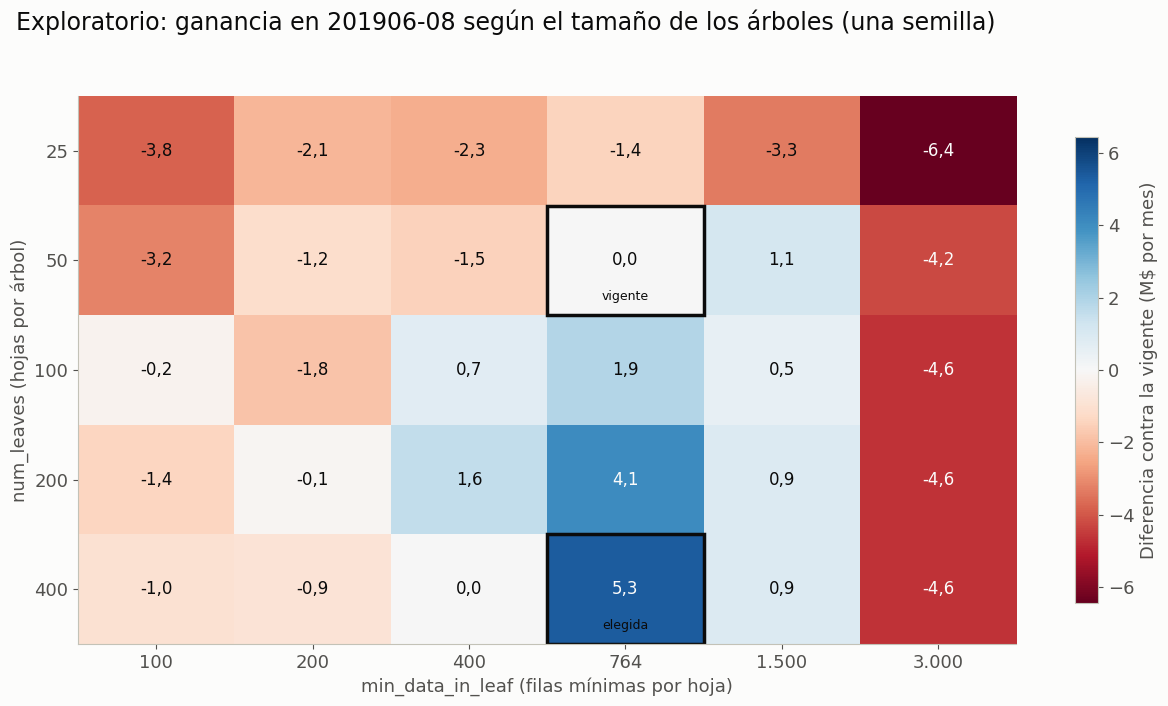

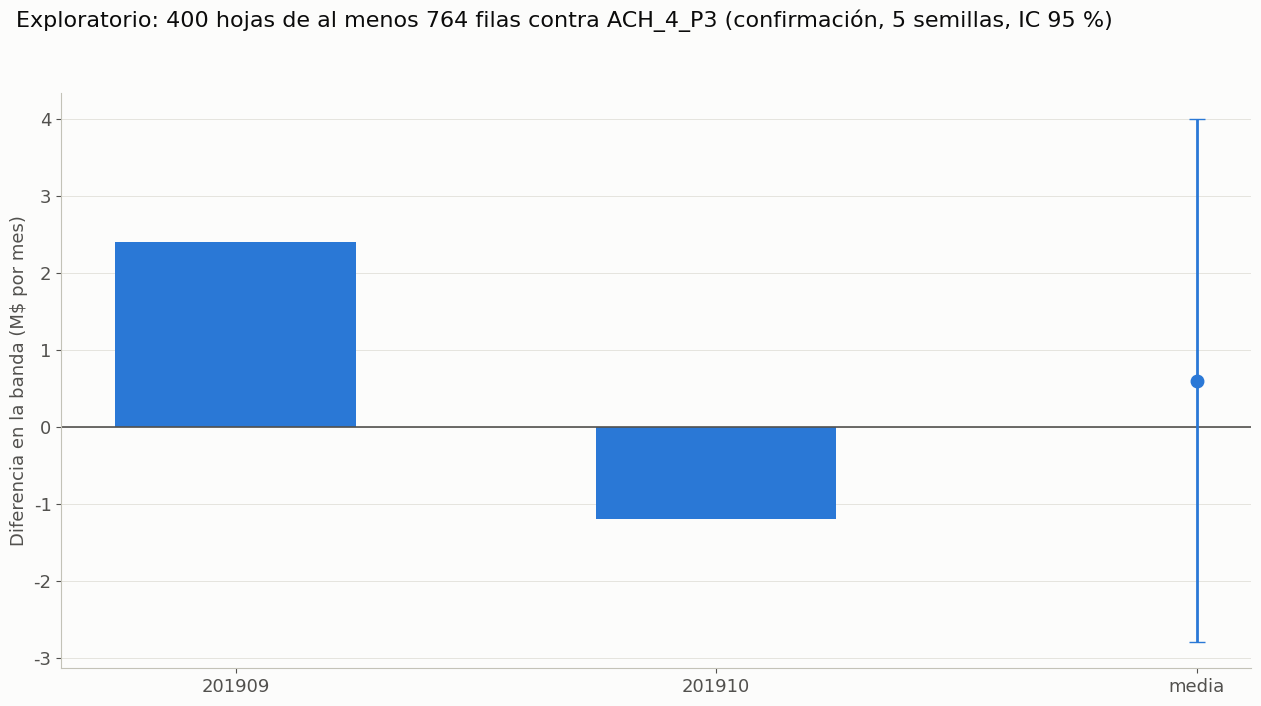

In [8]:
TINTA_2, GRILLA, AZUL = '#52514e', '#e1e0d9', '#2a78d6'
plt.rcParams.update({'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'axes.edgecolor': '#c3c2b7',
                     'axes.labelcolor': TINTA_2, 'xtick.color': TINTA_2, 'ytick.color': TINTA_2, 'text.color': '#0b0b0b',
                     'axes.grid': True, 'grid.color': GRILLA, 'grid.linewidth': 0.6, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 13, 'axes.titlesize': 15})
TAMANO, DPI = (12.8, 7.2), 150


def coma(x, decimales=1):
    return f'{x:,.{decimales}f}'.replace(',', '_').replace('.', ',').replace('_', '.')


from matplotlib.colors import TwoSlopeNorm

DIF = (MAPA - MAPA.loc[VIGENTE]).loc[GRILLA_HOJAS, GRILLA_TAMANO]
lim = max(float(np.abs(DIF.values).max()), 0.5)
fig, ax = plt.subplots(figsize=TAMANO)
im = ax.imshow(DIF.values, cmap='RdBu', norm=TwoSlopeNorm(vcenter=0, vmin=-lim, vmax=lim), aspect='auto')
for a in range(DIF.shape[0]):
    for b in range(DIF.shape[1]):
        v = DIF.values[a, b]
        ax.text(b, a, coma(v, 1), ha='center', va='center', fontsize=12, color='#fcfcfb' if abs(v) > 0.6 * lim else '#0b0b0b')
for (h, t), rotulo in ((VIGENTE, 'vigente'), (ELEGIDA, 'elegida')):
    a, b = GRILLA_HOJAS.index(h), GRILLA_TAMANO.index(t)
    ax.add_patch(plt.Rectangle((b - 0.5, a - 0.5), 1, 1, fill=False, lw=2.5, ec='#0b0b0b'))
    ax.text(b, a + 0.33, rotulo, ha='center', va='center', fontsize=9, color='#0b0b0b')
ax.set_xticks(range(len(GRILLA_TAMANO)), [coma(t, 0) for t in GRILLA_TAMANO])
ax.set_yticks(range(len(GRILLA_HOJAS)), GRILLA_HOJAS)
ax.set_xlabel('min_data_in_leaf (filas mínimas por hoja)')
ax.set_ylabel('num_leaves (hojas por árbol)')
ax.grid(False)
cb = fig.colorbar(im, ax=ax, shrink=0.85)
cb.set_label('Diferencia contra la vigente (M$ por mes)')
fig.suptitle('Exploratorio: ganancia en 201906-08 según el tamaño de los árboles (una semilla)', x=0.02, ha='left', fontsize=17)
fig.tight_layout(rect=(0, 0, 1, 0.95))
fig.savefig(FIGURAS / '19_1_mapa.png', dpi=DPI)
plt.show()

if comparacion is not None:
    r = comparacion.iloc[0]
    formato = FuncFormatter(lambda v, _: coma(v, 0 if float(v).is_integer() else 1))
    fig, ax = plt.subplots(figsize=TAMANO)
    ax.axhline(0, color=TINTA_2, lw=1.2)
    x = [str(m) for m in MESES_CONFIRMA] + ['media']
    ax.bar(x[:-1], [r[f'd_{m}'] for m in MESES_CONFIRMA], color=AZUL, width=0.5)
    ax.errorbar([x[-1]], [r.d_M], yerr=[[r.d_M - r.ic95_inf_M], [r.ic95_sup_M - r.d_M]], fmt='o', color=AZUL, ms=9, capsize=6, lw=2)
    ax.yaxis.set_major_formatter(formato)
    ax.set_ylabel('Diferencia en la banda (M$ por mes)')
    ax.grid(axis='x', visible=False)
    ax.set_axisbelow(True)
    fig.suptitle(f'Exploratorio: {ELEGIDA[0]} hojas de al menos {coma(ELEGIDA[1], 0)} filas contra ACH_4_P3 (confirmación, 5 semillas, IC 95 %)',
                 x=0.02, ha='left', fontsize=16)
    fig.tight_layout(rect=(0, 0, 1, 0.95))
    fig.savefig(FIGURAS / '19_2_confirmacion.png', dpi=DPI)
    plt.show()

## 9. Lectura fijada antes de correr

Decide solo la elegida contra `ACH_4_P3`, en 201909–10 con 5 semillas, con `d` = la diferencia media en la banda:

| `d` | Lectura |
|---|---|
| +1 M o más | Suma: la elegida pasa a ser la vigente |
| Entre −1 y +1 M | Empate: queda `ACH_4_P3` |
| −1 M o menos | Resta: queda `ACH_4_P3` |

Si la elegida es la vigente, no hay confirmación y queda `ACH_4_P3`. La diferencia en la búsqueda está inflada por haber elegido ahí, y no decide. El intervalo se informa siempre.

**Control 8:** las salidas anteriores no cambiaron.

In [9]:
assert huella_archivos() == HUELLA_INICIAL, 'Cambiaron las salidas anteriores'   # control 8
print(f'Control de salidas OK · {(time.time() - T_INICIO) / 60:.1f} min en total · memoria máxima {memoria_gb()} GB')
print()
print('EXPLORATORIO: no cambia el resultado de la regla pre-registrada.')
print()

lectura = lambda d: 'Suma' if d >= UMBRAL else ('Resta' if d <= -UMBRAL else 'Empate')
fila = {'config': nombre(*ELEGIDA), 'hipotesis': HIPOTESIS, 'contra': REFERENCIA, 'num_leaves': ELEGIDA[0], 'min_data_in_leaf': ELEGIDA[1],
        'd_busqueda_M': round(float(MAPA.loc[ELEGIDA] - MAPA.loc[VIGENTE]), 3)}
if comparacion is not None:
    r = comparacion.iloc[0]
    fila.update({'d_M': round(r.d_M, 3), 'resultado': lectura(r.d_M)})
    print(f'{r.config} contra {r.contra}: {r.d_M:+.2f} M ({r.ic95_inf_M:.2f} a {r.ic95_sup_M:.2f}) · error {r.error_total_M:.2f} M · '
          f'ensamble {r.d_ensamble_M:+.2f} M · semillas a favor {r.semillas_a_favor} de {N_SEMILLAS} · {lectura(r.d_M)} · DECIDE')
else:
    fila.update({'d_M': np.nan, 'resultado': 'La elegida es la vigente'})
    print('La elegida es la vigente: queda ACH_4_P3')
pd.DataFrame([fila]).to_csv(RESULTADOS / '19_iteraciones.tsv', sep='\t', index=False)

Control de salidas OK · 111.3 min en total · memoria máxima 6.3 GB

EXPLORATORIO: no cambia el resultado de la regla pre-registrada.

H400_M764 contra ACH_4_P3: +0.60 M (-2.80 a 3.99) · error 1.73 M · ensamble +1.15 M · semillas a favor 2 de 5 · Empate · DECIDE
